# TP1 — Clustering : segmenter une clientèle (Correction)

**Durée : 2 h** · Cours associé : [TP1_Cours.md](TP1_Cours.md) · Pense-bête : [Pense_bete_Pandas.md](../Pense_bete_Pandas.md)

## Contexte

Un centre commercial a collecté des informations sur 200 clients titulaires de sa carte de fidélité : sexe, âge, revenu annuel et un **score de dépense** (de 1 à 100) calculé à partir de leurs achats. Le service marketing vous demande d'identifier des **segments de clientèle** pour adapter ses campagnes.

Aucune étiquette n'est fournie : c'est un problème d'**apprentissage non supervisé**.

## Déroulé

| Partie | Contenu | Durée indicative |
|---|---|---|
| 1 | Exploration des données | 15 min |
| 2 | K-Means sur deux variables, choix de `k` | 30 min |
| 3 | K-Means sur trois variables, ACP, interprétation | 25 min |
| 4 | Synthèse pour le marketing | 10 min |
| 5 | *Facultatif* — Classification ascendante hiérarchique | 30 min |

Les cellules marquées `# TODO` sont à compléter. Les cellules ✍️ attendent une réponse rédigée.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA

plt.rcParams["figure.figsize"] = (8, 5)
RANDOM_STATE = 42

## Partie 1 — Exploration des données (15 min)

**1.1** Chargez le fichier `data/Mall_Customers.csv` dans un DataFrame `df`, puis renommez les colonnes en `id`, `sexe`, `age`, `revenu`, `score` pour faciliter la suite. Affichez les premières lignes.

In [2]:
# TODO : charger le fichier et renommer les colonnes
df = pd.read_csv("data/Mall_Customers.csv")
df.columns = ["id", "sexe", "age", "revenu", "score"]
df.head()

,id,sexe,age,revenu,score
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


**1.2** Vérifiez les dimensions, les types et l'absence de valeurs manquantes, puis affichez les statistiques descriptives.

In [3]:
# TODO : shape, info, valeurs manquantes, describe
print(df.shape)
df.info()
print(df.isna().sum())
df.describe()

(200, 5)
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   id      200 non-null    int64
 1   sexe    200 non-null    str  
 2   age     200 non-null    int64
 3   revenu  200 non-null    int64
 4   score   200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB
id        0
sexe      0
age       0
revenu    0
score     0
dtype: int64


,id,age,revenu,score
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


**1.3** Affichez la répartition hommes / femmes puis les histogrammes de `age`, `revenu` et `score`.

sexe
Female    112
Male       88
Name: count, dtype: int64


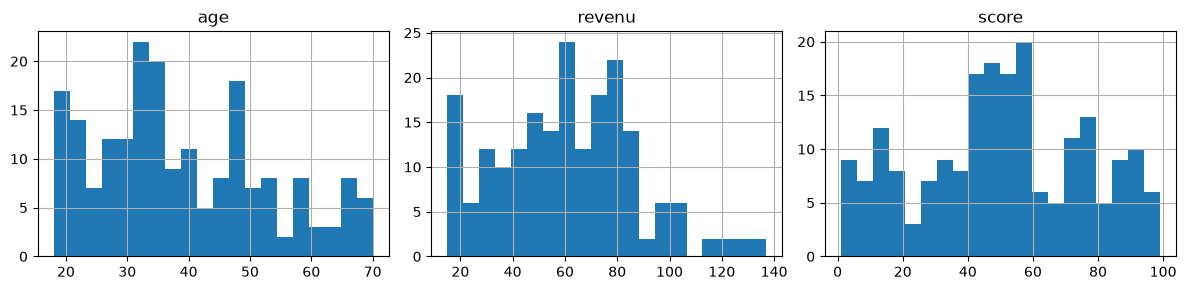

In [4]:
# TODO : répartition par sexe et histogrammes
print(df["sexe"].value_counts())
df[["age", "revenu", "score"]].hist(bins=20, figsize=(12, 3), layout=(1, 3))
plt.tight_layout()
plt.show()

**1.4** Tracez le nuage de points `revenu` (en abscisse) contre `score` (en ordonnée). Combien de groupes distinguez-vous à l'œil nu ?

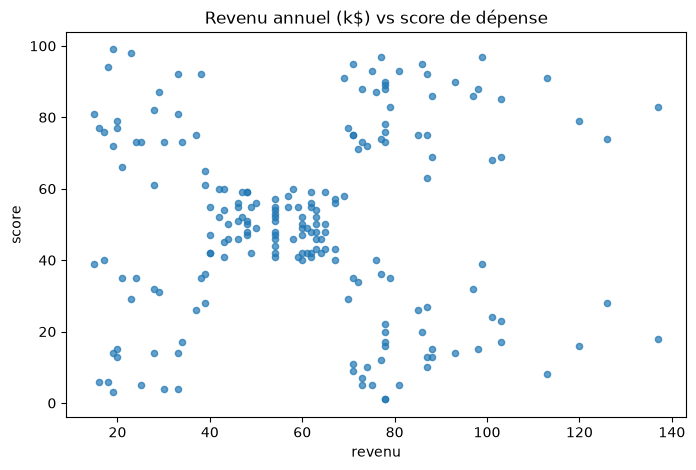

In [5]:
# TODO : nuage de points revenu / score
df.plot.scatter(x="revenu", y="score", alpha=0.7)
plt.title("Revenu annuel (k$) vs score de dépense")
plt.show()

✅ **Éléments de réponse**

On distingue nettement **5 groupes** : une masse centrale (revenu et score moyens) et quatre « coins » (revenu faible ou élevé, combiné à un score faible ou élevé).

## Partie 2 — K-Means sur deux variables (30 min)

On commence avec les deux variables `revenu` et `score`, ce qui permet de visualiser directement le résultat.

**2.1** Construisez la matrice `X2` contenant ces deux colonnes, puis standardisez-la avec un `StandardScaler` dans `X2_scaled`. Vérifiez que les moyennes valent 0 et les écarts-types 1.

In [6]:
# TODO : sélection et standardisation
X2 = df[["revenu", "score"]]
scaler2 = StandardScaler()
X2_scaled = scaler2.fit_transform(X2)
print(X2_scaled.mean(axis=0).round(3), X2_scaled.std(axis=0).round(3))

[-0. -0.] [1. 1.]


**2.2** Appliquez un K-Means avec `k = 5` (`n_init=10`, `random_state=RANDOM_STATE`). Ajoutez les étiquettes dans une colonne `cluster_k2` de `df`, puis tracez le nuage revenu / score coloré par cluster.

*Bonus : ajoutez les centroïdes sur le graphique, en unités d'origine (pensez à `scaler2.inverse_transform`).*

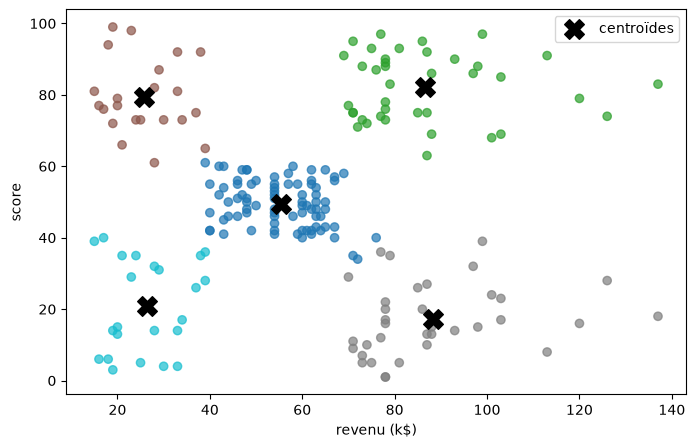

In [7]:
# TODO : K-Means à 5 clusters et visualisation
kmeans2 = KMeans(n_clusters=5, n_init=10, random_state=RANDOM_STATE)
df["cluster_k2"] = kmeans2.fit_predict(X2_scaled)

# Reconvertit les centres des groupes dans leurs unités d'origine (revenu en milliers de dollars, score de 1 à 100),
# pour pouvoir les placer sur le graphique.
centres = scaler2.inverse_transform(kmeans2.cluster_centers_)
plt.scatter(df["revenu"], df["score"], c=df["cluster_k2"], cmap="tab10", alpha=0.7)
plt.scatter(centres[:, 0], centres[:, 1], c="black", marker="X", s=200, label="centroïdes")
plt.xlabel("revenu (k$)")
plt.ylabel("score")
plt.legend()
plt.show()

**2.3** Méthode du coude : pour `k` allant de 1 à 10, entraînez un K-Means et stockez son inertie (`inertia_`). Tracez l'inertie en fonction de `k`.

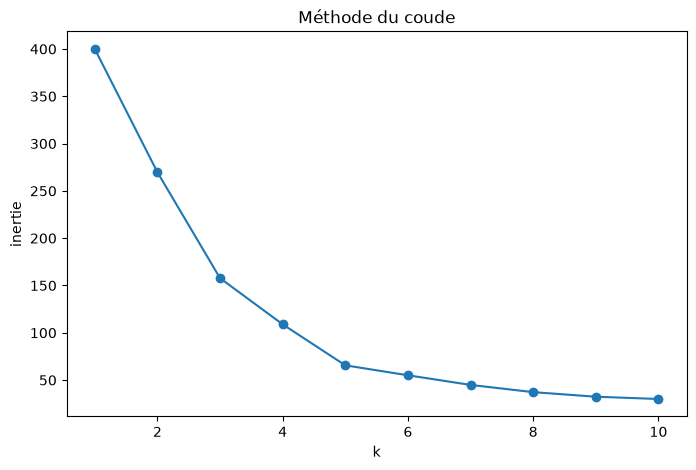

In [8]:
# TODO : courbe du coude
ks = range(1, 11)
inerties = []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X2_scaled)
    inerties.append(km.inertia_)

plt.plot(ks, inerties, marker="o")
plt.xlabel("k")
plt.ylabel("inertie")
plt.title("Méthode du coude")
plt.show()

**2.4** Faites de même avec le score de silhouette pour `k` allant de 2 à 10 (pourquoi pas `k = 1` ?). Quel `k` retenez-vous ?

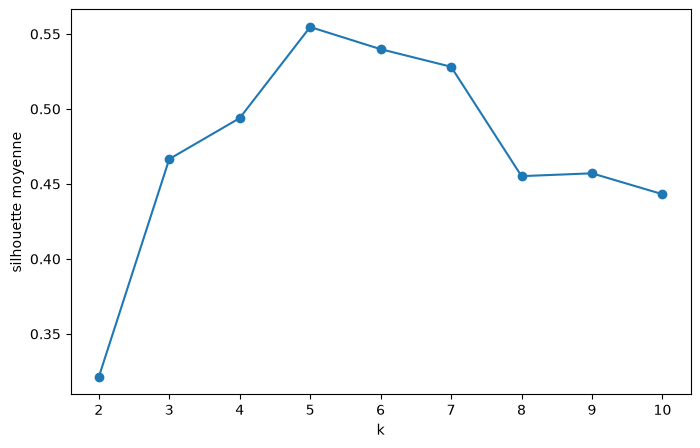

meilleur k : 5


In [9]:
# TODO : score de silhouette en fonction de k
ks_sil = range(2, 11)
silhouettes = []
for k in ks_sil:
    labels = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(X2_scaled)
    silhouettes.append(silhouette_score(X2_scaled, labels))

plt.plot(ks_sil, silhouettes, marker="o")
plt.xlabel("k")
plt.ylabel("silhouette moyenne")
plt.show()
print("meilleur k :", ks_sil[int(np.argmax(silhouettes))])

✅ **Éléments de réponse**

- La silhouette n'est pas définie pour `k = 1` : il n'existe pas de cluster voisin, donc pas de `b(i)`.
- Le coude est visible à `k = 5` et la silhouette y atteint son maximum (≈ 0,55). Les deux critères concordent avec l'intuition visuelle de la question 1.4 : on retient **k = 5**.

**2.5** Que se passe-t-il si l'on **ne standardise pas** ? Relancez K-Means (`k = 5`) sur `X2` brut et comparez les étiquettes obtenues avec `cluster_k2` grâce à `adjusted_rand_score` (1 = partitions identiques, 0 = accord dû au hasard). Pourquoi l'effet est-il faible ici ? Dans quel cas serait-il important ?

In [10]:
# TODO : K-Means sans standardisation et comparaison
labels_brut = KMeans(n_clusters=5, n_init=10, random_state=RANDOM_STATE).fit_predict(X2)
adjusted_rand_score(df["cluster_k2"], labels_brut)

1.0

✅ **Éléments de réponse**

Les deux partitions sont identiques (ARI = 1) car `revenu` (15 à 137) et `score` (1 à 99) ont des **échelles comparables**. En revanche, si le revenu était exprimé en euros (15 000 à 137 000), il écraserait totalement le score et K-Means ne découperait plus que selon le revenu. Standardiser est une bonne habitude : cela ne coûte rien et protège de ce piège.

## Partie 3 — K-Means sur trois variables (25 min)

On ajoute maintenant l'`age`.

**3.1** Construisez `X3` avec `age`, `revenu`, `score`, standardisez-la dans `X3_scaled`, puis tracez côte à côte la courbe du coude et celle de la silhouette pour `k` de 2 à 10. Quel `k` choisissez-vous ?

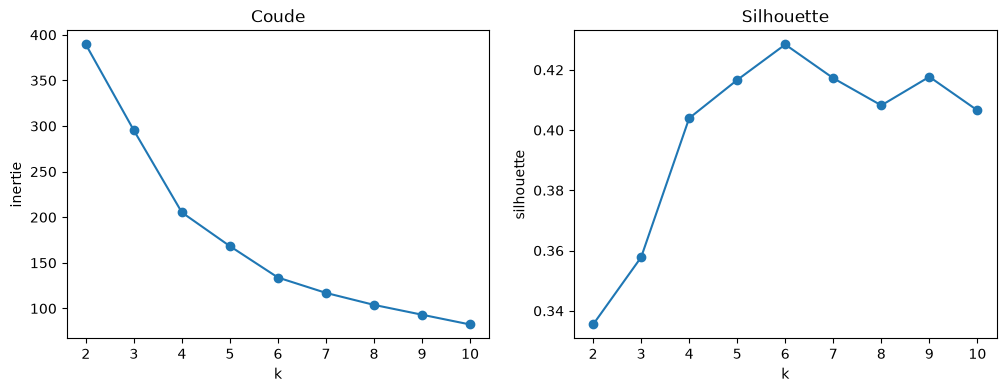

In [11]:
# TODO : standardisation et choix de k sur 3 variables
X3 = df[["age", "revenu", "score"]]
X3_scaled = StandardScaler().fit_transform(X3)

ks3 = range(2, 11)
inerties3, silhouettes3 = [], []
for k in ks3:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X3_scaled)
    inerties3.append(km.inertia_)
    silhouettes3.append(silhouette_score(X3_scaled, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(ks3, inerties3, marker="o")
axes[0].set(title="Coude", xlabel="k", ylabel="inertie")
axes[1].plot(ks3, silhouettes3, marker="o")
axes[1].set(title="Silhouette", xlabel="k", ylabel="silhouette")
plt.show()

✅ **Éléments de réponse**

Le coude est moins net qu'en deux dimensions. La silhouette est maximale autour de **k = 6** (valeurs de `k = 5` à `7` très proches). On retient `k = 6`, en gardant en tête que `k = 5` serait aussi défendable : c'est l'interprétation (question 3.3) qui tranche.

**3.2** Entraînez le K-Means avec le `k` retenu (colonne `cluster`). Comme on ne peut pas tracer 3 dimensions facilement, projetez `X3_scaled` sur 2 axes avec une ACP (`PCA(n_components=2)`) et colorez les points par cluster. Quelle part de la variance les deux axes conservent-ils ?

variance expliquée : [0.44 0.33] total : 0.78


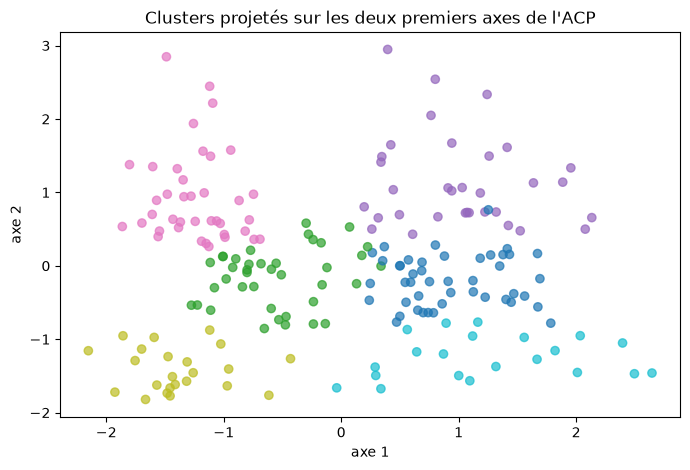

In [12]:
# TODO : K-Means final et projection ACP
K = 6
kmeans3 = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE)
df["cluster"] = kmeans3.fit_predict(X3_scaled)

pca = PCA(n_components=2)
X3_2d = pca.fit_transform(X3_scaled)
print("variance expliquée :", pca.explained_variance_ratio_.round(2), "total :", pca.explained_variance_ratio_.sum().round(2))

plt.scatter(X3_2d[:, 0], X3_2d[:, 1], c=df["cluster"], cmap="tab10", alpha=0.7)
plt.xlabel("axe 1")
plt.ylabel("axe 2")
plt.title("Clusters projetés sur les deux premiers axes de l'ACP")
plt.show()

**3.3** Calculez le **profil moyen** de chaque cluster (âge, revenu, score, effectif, part de femmes). Donnez un nom parlant à chaque segment.

*Indice : `groupby` + `agg`, et `(df["sexe"] == "Female").mean()` donne une proportion.*

In [13]:
# TODO : profil des clusters
profil = (
    df.assign(femme=df["sexe"] == "Female")
    .groupby("cluster")
    .agg(effectif=("id", "size"),
         age=("age", "mean"),
         revenu=("revenu", "mean"),
         score=("score", "mean"),
         part_femmes=("femme", "mean"))
    .round(1)
    .sort_values("revenu")
)
profil

,effectif,age,revenu,score,part_femmes
cluster,,,,,
4,23,25.0,25.3,77.6,0.6
5,21,45.5,26.3,19.4,0.6
0,45,56.3,54.3,49.1,0.6
1,39,26.8,57.1,48.1,0.6
3,39,32.7,86.5,82.1,0.5
2,33,41.9,88.9,17.0,0.4


✅ **Éléments de réponse**

Les numéros de clusters peuvent varier, mais on retrouve typiquement :

| Segment | Profil |
|---|---|
| Jeunes dépensiers modestes | ~25 ans, revenu faible, score élevé |
| Prudents modestes | ~45 ans, revenu faible, score faible |
| Classe moyenne jeune | ~27 ans, revenu moyen, score moyen |
| Classe moyenne senior | ~56 ans, revenu moyen, score moyen |
| Clients premium | ~33 ans, revenu élevé, score élevé |
| Aisés économes | ~41 ans, revenu élevé, score faible |

Par rapport à la partie 2, l'âge a scindé le groupe central en deux (jeunes / seniors). La part de femmes varie peu d'un segment à l'autre : le sexe n'est pas discriminant ici.

## Partie 4 — Synthèse pour le service marketing (10 min)

Rédigez en quelques lignes :

1. la segmentation que vous recommandez (algorithme, variables, nombre de segments) ;
2. une action marketing pour deux segments de votre choix ;
3. une limite de votre analyse.

✅ **Éléments de réponse**

1. **K-Means à 6 segments** sur l'âge, le revenu et le score de dépense standardisés : la silhouette est maximale pour ce découpage, et chaque segment s'interprète facilement.
2. Exemples d'actions :
   - *Clients premium* (revenu et score élevés) : programme de fidélité haut de gamme, avant-premières.
   - *Aisés économes* (revenu élevé, score faible) : fort potentiel inexploité, campagnes ciblées sur la qualité ou les services.
   - *Jeunes dépensiers modestes* : attention au surendettement ; promotions sur les petits prix, paiement fractionné.
3. Limites : seulement 200 clients ; le score de dépense est une boîte noire calculée par le centre commercial ; la segmentation est statique et devra être recalculée régulièrement ; le choix de `k` garde une part de subjectivité.

## Partie 5 — *Facultatif* : classification ascendante hiérarchique (30 min)

> Cette partie est **facultative** : faites-la si vous avez terminé les parties 1 à 4. Elle s'appuie sur la section « Pour aller plus loin : la CAH » du cours.

**5.1** Calculez la matrice de liaison de `X3_scaled` avec la méthode de Ward (`scipy.cluster.hierarchy.linkage`) et affichez le dendrogramme (tronqué aux 30 dernières fusions pour la lisibilité). Où couperiez-vous l'arbre ?

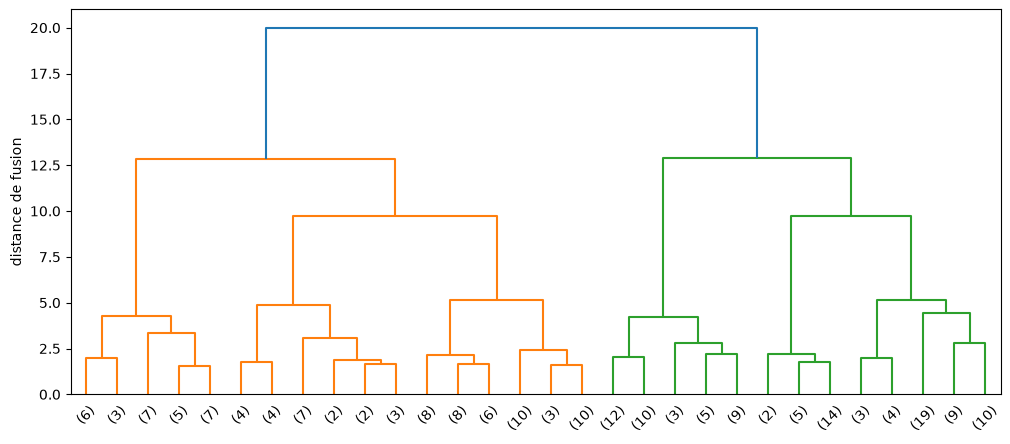

In [14]:
from scipy.cluster.hierarchy import linkage, dendrogram

# TODO : dendrogramme
Z = linkage(X3_scaled, method="ward")
plt.figure(figsize=(12, 5))
dendrogram(Z, truncate_mode="lastp", p=30)
plt.ylabel("distance de fusion")
plt.show()

✅ **Éléments de réponse**

Les plus grands sauts de hauteur se situent entre 2 et 6 groupes. Une coupe donnant **5 ou 6 groupes** laisse de longues branches verticales au-dessus de la coupe : ce découpage est cohérent avec celui trouvé par K-Means.

**5.2** Appliquez `AgglomerativeClustering` avec le même nombre de clusters que K-Means et la liaison `ward`. Comparez les deux partitions avec `adjusted_rand_score` et un tableau croisé (`pd.crosstab`).

In [15]:
# TODO : CAH et comparaison avec K-Means
cah = AgglomerativeClustering(n_clusters=K, linkage="ward")
df["cluster_cah"] = cah.fit_predict(X3_scaled)
print("ARI K-Means / CAH :", round(adjusted_rand_score(df["cluster"], df["cluster_cah"]), 3))
pd.crosstab(df["cluster"], df["cluster_cah"])

ARI K-Means / CAH : 0.891


cluster_cah,0,1,2,3,4,5
cluster,,,,,,
0,2,43,0,0,0,0
1,39,0,0,0,0,0
2,3,2,0,28,0,0
3,0,0,39,0,0,0
4,1,0,0,0,1,21
5,0,0,0,0,21,0


**5.3** Testez la liaison `single` à la place de `ward` et regardez les effectifs par cluster. Que constatez-vous ?

In [16]:
# TODO : liaison single
labels_single = AgglomerativeClustering(n_clusters=K, linkage="single").fit_predict(X3_scaled)
pd.Series(labels_single).value_counts()

0    193
2      2
1      2
3      1
4      1
5      1
Name: count, dtype: int64

✅ **Éléments de réponse**

- Avec Ward, les deux méthodes s'accordent largement (ARI ≈ 0,89) : chaque cluster K-Means correspond presque entièrement à un cluster CAH. Deux algorithmes très différents trouvant la même structure, c'est un argument fort en faveur de la segmentation retenue.
- Avec la liaison `single`, on obtient un énorme cluster de 193 clients et quelques clusters d'un ou deux individus : c'est l'**effet de chaîne**. Deux groupes sont fusionnés dès que deux de leurs points sont proches, si bien que tout finit par s'agglomérer. Cette liaison est inadaptée à la segmentation.

## Pour aller plus loin (bonus)

- Remplacez K-Means par un **mélange gaussien** (`sklearn.mixture.GaussianMixture`) et affichez, pour quelques clients, la probabilité d'appartenir à chaque segment (`predict_proba`).
- Tracez le **diagramme de silhouette** individuel (une barre par client, groupées par cluster) pour repérer les clients mal classés.

In [17]:
# Bonus : mélange gaussien
from sklearn.mixture import GaussianMixture

gmm = GaussianMixture(n_components=K, random_state=RANDOM_STATE).fit(X3_scaled)
probas = pd.DataFrame(gmm.predict_proba(X3_scaled).round(2), columns=[f"seg_{i}" for i in range(K)])
probas.head(10)

,seg_0,seg_1,seg_2,seg_3,seg_4,seg_5
0,0.0,0.0,0.00,0.00,0.0,1.0
1,0.0,0.0,1.00,0.00,0.0,0.0
2,0.0,0.0,0.00,0.00,0.0,1.0
3,0.0,0.0,1.00,0.00,0.0,0.0
4,0.0,0.0,0.00,0.00,0.0,1.0
5,0.0,0.0,1.00,0.00,0.0,0.0
6,0.0,0.0,0.00,0.00,0.0,1.0
7,0.0,0.0,0.97,0.03,0.0,0.0
8,0.0,0.0,0.00,0.00,0.0,1.0
9,0.0,0.0,0.86,0.13,0.0,0.0
